# Module 4 — Customer Analytics: run the whole module

**How to use:**
- **Run all** to run the full module in order, or run a single cell to run one step.
- Each cell runs one task notebook in full and shows all its charts and main tables here; the task notebook itself shows every table.
- Every task notebook also runs on its own: open it from `notebooks/` and run all.

**Order matters:** later tasks read the files earlier tasks save in `outputs/taskN/`.

| Step | Notebook | Status |
| --- | --- | --- |
| 0. Data check | `helpers/m04_data.py` | Built |
| 1. Task 1 — Churn prediction | `notebooks/m04_task1_churn.ipynb` | Built |
| 2. Task 2 — Customer Lifetime Value | `notebooks/m04_task2_clv.ipynb` | Built |
| 3. Task 3 — Customer prioritization and the executive question | `notebooks/m04_task3_prioritisation.ipynb` | Built |
| Final. Output workbook | `helpers/m04_final_output.py` → `outputs/FINAL_M4_module_output.xlsx` | Built |

Findings with charts: `reports/`. Status: `docs/progress.md`.


## Setup
Moves into the module folder so the paths below work, both locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.

In [1]:
import os
import sys
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]
os.chdir(PROJECT_ROOT / "module_04_customer_analytics")                  # the paths below start from the module folder
print("Working folder:", Path.cwd().name)

Working folder: module_04_customer_analytics


## 0. Data check
Is `nova_customers.csv` complete and clean? Prints rows, missing values, duplicates, churners, churn rate and CLV.

In [2]:
%run helpers/m04_data.py

rows: 5000
missing_values: 0
duplicate_ids: 0
churners: 89
churn_rate: 0.0178
clv_mean: 65602.0
clv_zero: 17


## 1. Task 1 — Churn prediction
Runs `notebooks/m04_task1_churn.ipynb` (about 12 minutes, mostly the shuffled-label test).
- each column tested; four models and a 115-input feature-engineering check over 25 rounds;
- each model against 100 runs on shuffled labels; churners in the top 1,000 against random picking;
- why the data isn't rebalanced; what drives churn;
- saves `outputs/task1/FINAL_M4_T1_churn_scores.csv` for Task 3.

nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


Outputs go to: module_04_customer_analytics/outputs/task1
           rows: 5000
 missing_values: 0
  duplicate_ids: 0
       churners: 89
     churn_rate: 0.0178
       clv_mean: 65602.0
       clv_zero: 17
Churn rate 1.78% (95% range 1.45% to 2.19%): 89 churners of 5,000
                 Age: min 21, max 75, negative: 0
       Annual_Income: min 76,777, max 9,111,731, negative: 0
     Account_Balance: min 15,027, max 5,756,059, negative: 0
        Loan_Balance: min 53, max 8,525,613, negative: 0
  Investment_Balance: min 43, max 11,804,786, negative: 0
       Digital_Usage: min 0, max 100, negative: 0

Median CLV: churners ₹55,579, stayers ₹54,195
Churn rate by CLV fifth: ['1.4%', '2.0%', '2.1%', '2.0%', '1.4%'] (do they differ? p = 0.59)
Complaints_Per_Year  = Complaints ÷ Relationship_Length_Years  (how often the customer complains)
Total_Balances       = Account_Balance + Loan_Balance + Investment_Balance  (size of the relationship)
Balance_Per_Product  = Total_Balances ÷ Products_

Significance line: 0.05 ÷ 15 = 0.0033;  columns below it: 0 of 15


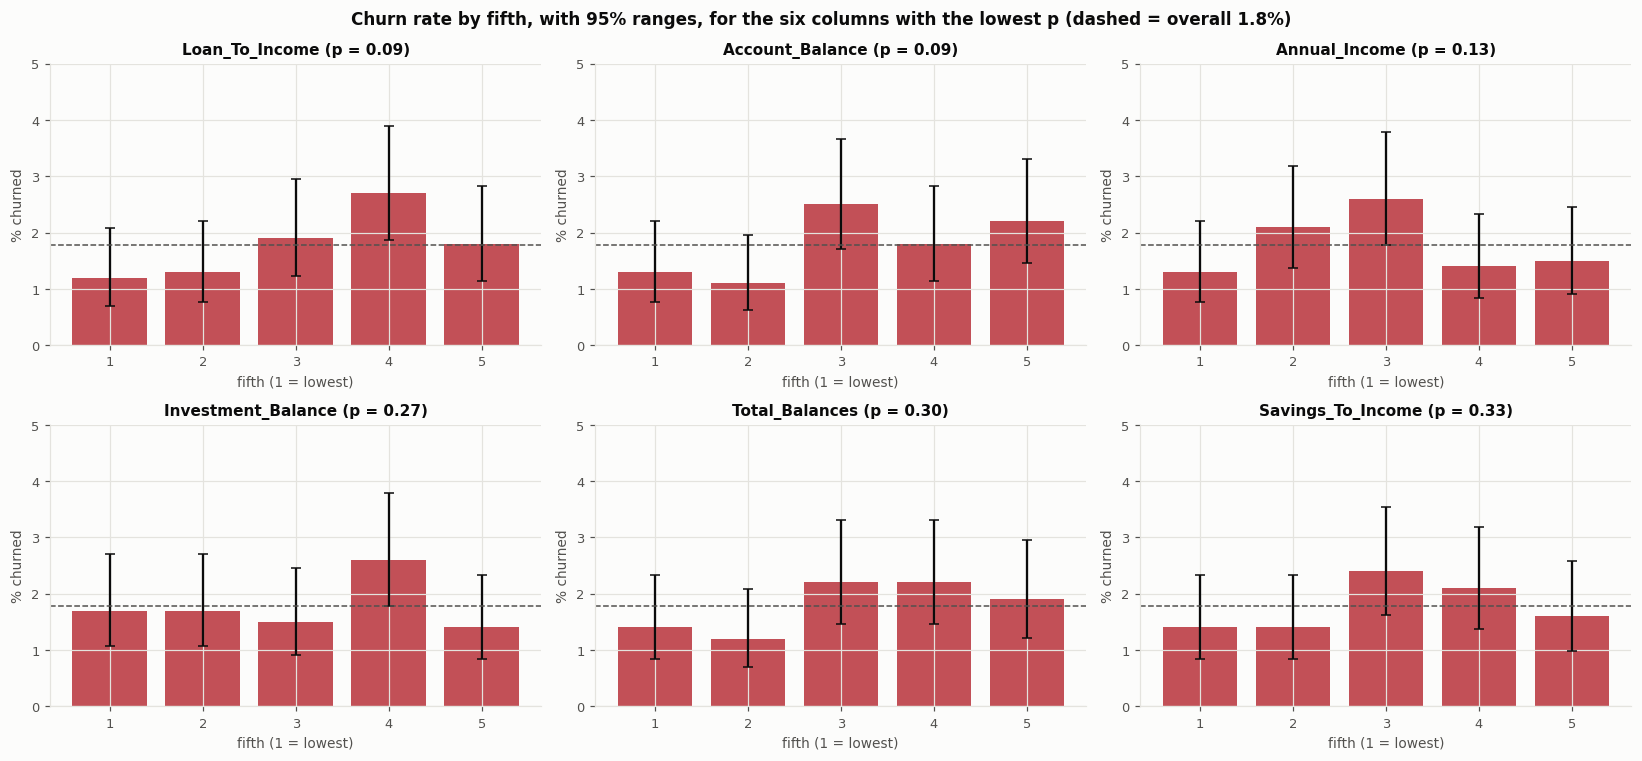

Broad search inputs: 115


Logistic regression                       1s | ROC-AUC 0.490 | PR-AUC 0.0235 | Brier 0.0176


Decision tree                             1s | ROC-AUC 0.489 | PR-AUC 0.0191 | Brier 0.0177


Random forest                            22s | ROC-AUC 0.502 | PR-AUC 0.0304 | Brier 0.0176


LightGBM                                  2s | ROC-AUC 0.495 | PR-AUC 0.0236 | Brier 0.0177


LightGBM, broad search (115 inputs)       7s | ROC-AUC 0.561 | PR-AUC 0.0265 | Brier 0.0177


... (3 outputs left out)

Random forest                           464s | real 0.510 | shuffled mean 0.504, 95th 0.565 | p 0.455


LightGBM                                 36s | real 0.474 | shuffled mean 0.498, 95th 0.568 | p 0.733


LightGBM, broad search (115 inputs)     144s | real 0.534 | shuffled mean 0.504, 95th 0.562 | p 0.198


Pass line: 0.05 ÷ 5 set-ups = 0.010;  smallest possible p with 100 shuffles = 0.0099


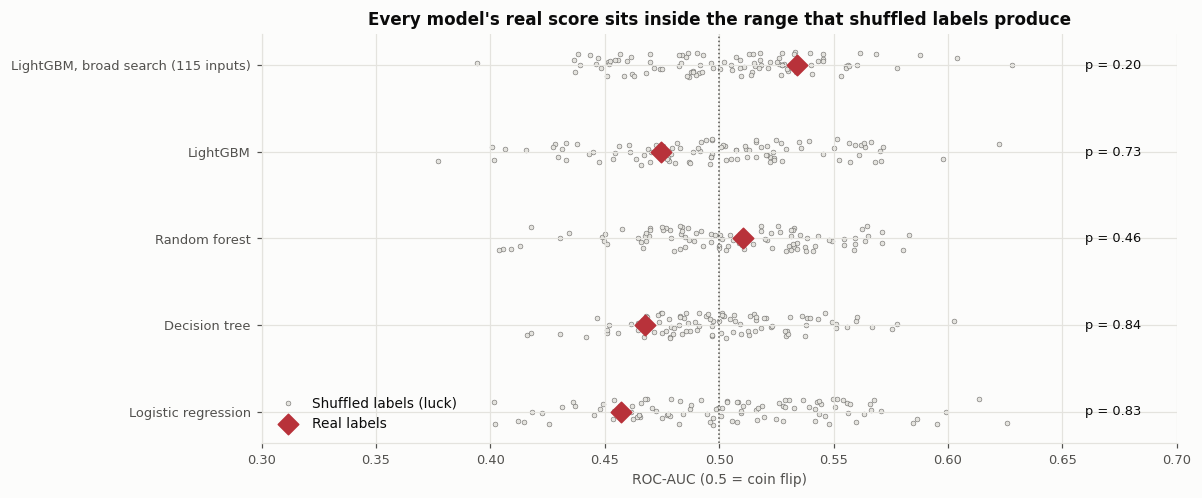

Random picking reaches 1000 ÷ 5,000 = 20% of churners = 17.8 of 89
Random picking reaches 17.8 of 89 churners (20%)


The broad search's top 8 inputs by importance (gain):
Account_Balance × Loan_Balance (ln)              0.050
Annual_Income                                    0.036
Products_Held ÷ Complaints                       0.035
Loan_Balance × Relationship_Length_Years (ln)    0.034
Transactions_Per_Month × Loan_Balance (ln)       0.033
Products_Held × Digital_Usage (ln)               0.030
Products_Held ÷ Digital_Usage                    0.028
Digital_Usage × Investment_Balance (ln)          0.025


Actual churn rate: 1.78%;  Brier when guessing the churn rate for everyone: 0.0175
Significant drivers: 0 of 10;  whole-model test (all weights zero?): p = 0.63
Churn predictable from this data: False;  scores handed to Task 3: Logistic regression
Saved to module_04_customer_analytics/outputs/task1
['01_churn_by_column.png', '02_shuffled_label_test.png', 'FINAL_M4_T1_churn_scores.csv', 'churn_model.joblib', 'evidence_table.csv', 'key_numbers.json', 'model_tests.csv']


In [3]:
%run notebooks/m04_task1_churn.ipynb

## 2. Task 2 — Customer Lifetime Value
Runs `notebooks/m04_task2_clv.ipynb` (about 1 minute).
- five regression models compared over 25 rounds;
- the CLV rule found from the data, each weight explained, and what CLV leaves out;
- where the ₹32.8 crore of value sits;
- saves `outputs/task2/FINAL_M4_T2_customer_value.csv` for Task 3.

Outputs go to: module_04_customer_analytics/outputs/task2
Customers: 5,000;  total CLV ₹32.80 crore
CLV: mean ₹65,602, median ₹54,205, smallest ₹0, largest ₹439,367
Customers with CLV exactly ₹0: 17
Median CLV: churners ₹55,579, stayers ₹54,195


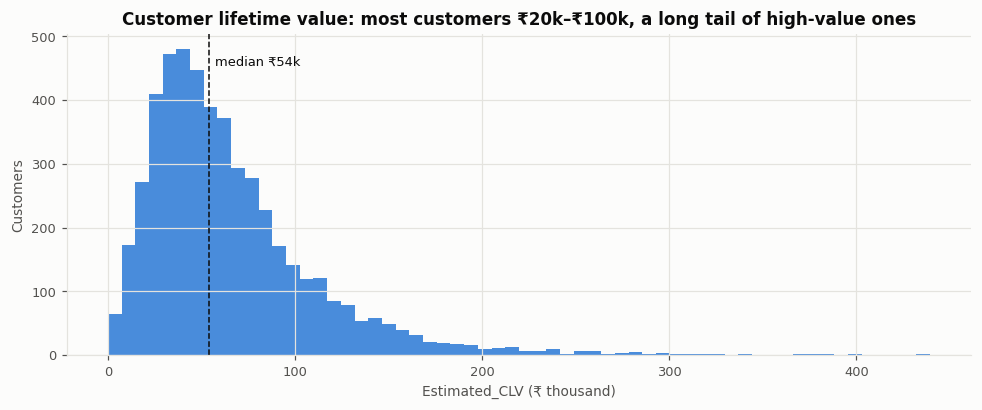

Linear regression     0s


Lasso                 2s


Decision tree         1s


Random forest        61s


LightGBM             15s


Lowest RMSE: Linear regression;  chosen (simplest within chance of the best): Linear regression


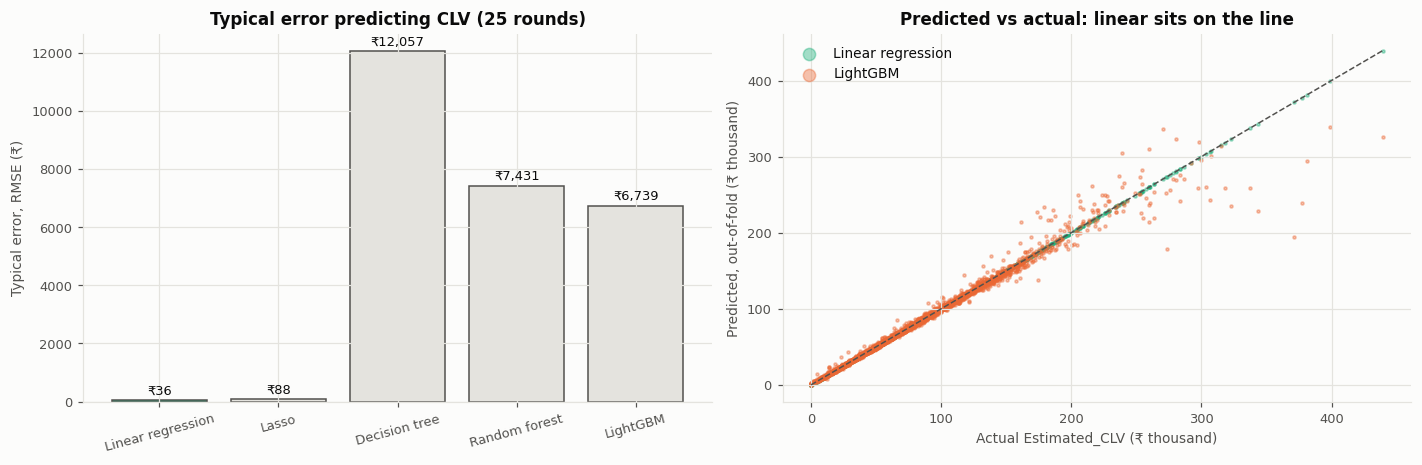

Fit on 4,983 positive-CLV customers: R² = 1.000000
Lasso switches off: ['Age', 'Products_Held', 'Transactions_Per_Month', 'Digital_Usage', 'Relationship_Length_Years']
CLV = max(0,  4% × Annual_Income + 3% × Account_Balance + 1.2% × Loan_Balance + 1.8% × Investment_Balance − ₹5,000 × Complaints)
Largest gap between the rule and Estimated_CLV, over all 5,000 customers: ₹0.0053
Customers differing by more than ₹1: 0;  customers at ₹0 under the rule: 17

Example, customer 300001: 4% × ₹515,268 + 3% × ₹898,438 + 1.2% × ₹392,907 + 1.8% × ₹1,933,424 − ₹5,000 × 1 = ₹82,080.38 (Estimated_CLV ₹82,080.38)


,₹ crore,Share of total before flooring
From income (4%),₹21.16,65%
From account balance (3%),₹6.81,21%
From loans (1.2%),₹2.74,8%
From investments (1.8%),₹5.91,18%
"Complaints (−₹5,000 each)",₹-3.81,-12%


Top customers by CLV,Share of customers,CLV (₹ crore),Share of total CLV,Lowest CLV in the group
100,2%,₹2.51,8%,"₹198,245"
500,10%,₹8.47,26%,"₹122,407"
"1,000",20%,₹13.79,42%,"₹93,019"
"2,500",50%,₹24.45,75%,"₹54,206"


Complaints cost ₹3.81 crore of value across 7,630 complaints


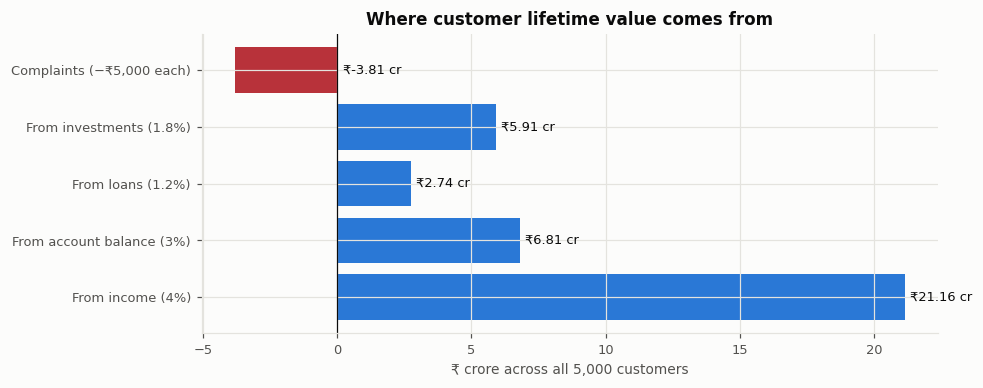

Saved to module_04_customer_analytics/outputs/task2
['01_clv_distribution.png', '02_model_comparison.png', '03_clv_sources.png', 'FINAL_M4_T2_customer_value.csv', 'key_numbers.json', 'model_comparison.csv']


In [4]:
%run notebooks/m04_task2_clv.ipynb

## 3. Task 3 — Customer prioritization and the executive question
Runs `notebooks/m04_task3_prioritisation.ipynb` (under a minute; needs Tasks 1 and 2 first).
- the four groups (High / Low CLV × High / Low churn score), each with its actual churn rate;
- the 1,000 customers to contact, back-tested against other ways of choosing;
- the break-even: how good calls must be to pay off;
- saves `outputs/task3/FINAL_M4_T3_contact_list.csv`, the answer to the executive question.

Outputs go to: module_04_customer_analytics/outputs/task3
Customers 5,000;  churn scores: No: scores no better than chance
Actual churn rate 1.78% (89 of 5,000);  total CLV ₹32.80 crore
High CLV: CLV ≥ ₹92,963 (top 20% = 1,000 ÷ 5,000)
High churn: chance of churn above 1.78% (= 89 ÷ 5,000);  customers above it: 2,132
Do the four groups churn differently? chi-square p = 0.67
High vs Low churn level (all customers): actual churn 1.88% vs 1.71%, p = 0.74


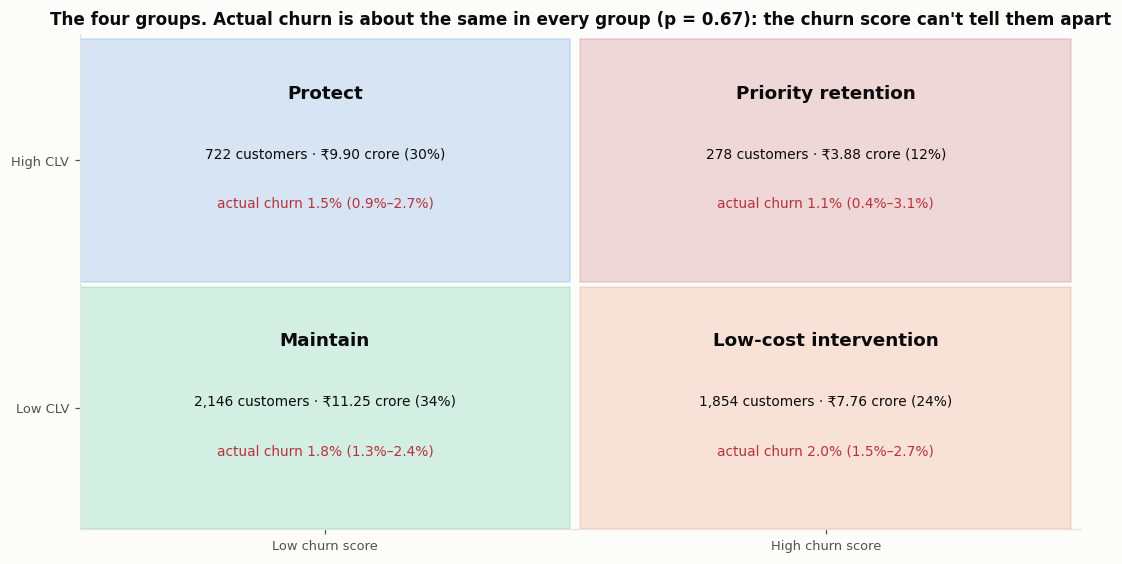

The 1,000: 278 Priority retention, then 722 Protect
They hold ₹13.79 crore (42% of all value); CLV ₹93,019 to ₹439,367
Value that left with the 89 leavers: ₹56.0 lakh


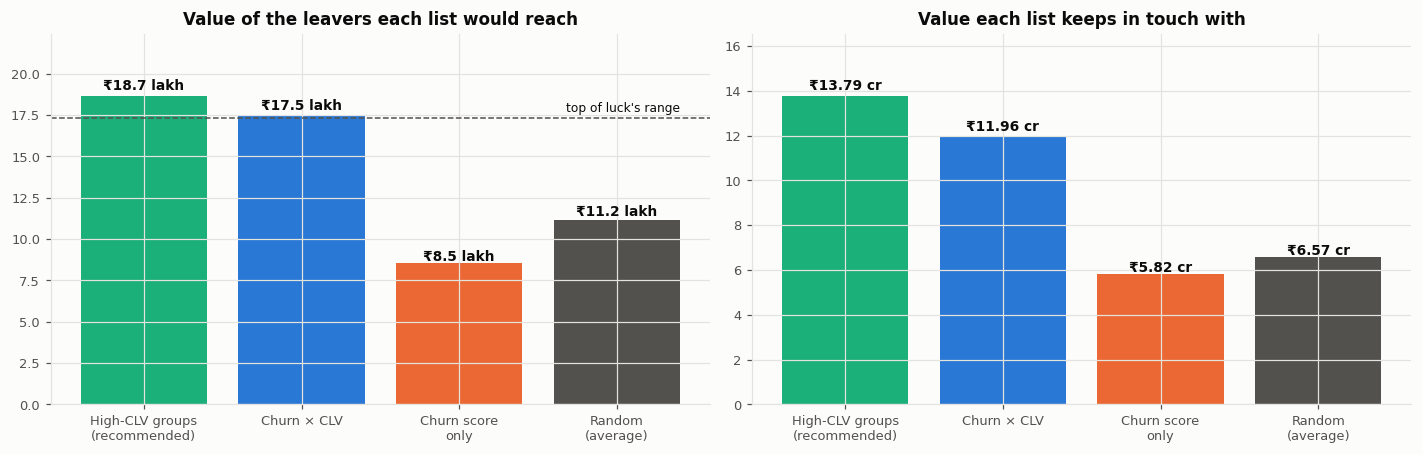

Whole list: expected loss if nobody is called = 1.78% × ₹13.79 crore = ₹24.5 lakh
  at ₹100 a call, 1,000 calls cost ₹1.0 lakh → calls must keep at least 4% of would-be leavers
  at ₹250 a call, 1,000 calls cost ₹2.5 lakh → calls must keep at least 10% of would-be leavers
  at ₹500 a call, 1,000 calls cost ₹5.0 lakh → calls must keep at least 20% of would-be leavers
  at ₹1,000 a call, 1,000 calls cost ₹10.0 lakh → calls must keep at least 41% of would-be leavers
Saved to module_04_customer_analytics/outputs/task3
['01_four_groups.png', '02_backtest.png', 'FINAL_M4_T3_contact_list.csv', 'customer_groups.csv', 'key_numbers.json', 'module9_inputs.csv']
Wealth fee income: 1.77% of client balances a year (bad year 1.39%); sample book ₹328.1 crore


,0
Category,Wealth management: fees on client balances
What NovaFin would put money into,Wealth management (sample book: ₹328.1 crore o...
Return per ₹ deployed (% a year),1.77
Return range (% a year),"1.39 (bad year) to 1.80 (no churn), per ₹ of c..."
Bad-year result per ₹ (% a year),1.39
How the bad year is defined,Market fall of 20% (balances and fees fall wit...
Capacity (₹ crore),328.1
Evidence strength,Medium: fee yield read from the CLV formula (e...
How fast the money can come back,Client money stays with clients; fees arrive y...
Data gap or assumption,"Per ₹ of client balances, not of NovaFin's cap..."


In [5]:
%run notebooks/m04_task3_prioritisation.ipynb

## Final output workbook
Builds **`outputs/FINAL_M4_module_output.xlsx`**: the one file to open for this module's results (project decision P-21).
- Tabs: Read me · Key numbers · Board actions · each task's final file · Hand-off to Module 9 · Decisions · Evidence index.
- Every hand-off figure is computed from the task tabs' rows, and each row says which tab, column(s) and rows it comes from.
- Run after all the tasks above.

In [6]:
%run helpers/m04_final_output.py

Saved: FINAL_M4_module_output.xlsx
                                                     Figure                                                                                                           Value                                             Unit                                         Status
                           Fee yield on investment balances                                                                                                             1.8                             % of balances a year Measured (+ our reading that it is fee income)
                   Investment balances in the customer file                                                                                                          328.06                                          ₹ crore                                       Measured
              Churn loss: share of balances held by leavers                                                                                                      